In [11]:
import os
print([f for f in os.listdir('.') if f.endswith('.csv')])

['3) Sentiment dataset.csv', 'churn-bigml-20.csv', 'vehicles.csv', 'scraped_quotes_dataset.csv', 'spam.csv', 'sales_data.csv', 'codveda_level1_task1_quotes.csv', 'codveda_level1_task2_preprocessed.csv', 'creditcard.csv', '4) house Prediction Data Set.csv', 'Advertising.csv', 'cardekho_dataset.csv', 'churn-bigml-80.csv', 'customer_segmentation_data.csv', '1) iris.csv']


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load sales_data.csv and inspect columns
df_sales = pd.read_csv('sales_data.csv')
print("Shape:", df_sales.shape)
print("Columns:", df_sales.columns.tolist())
print("\nMissing values:\n", df_sales.isnull().sum())
print("\nFirst 5 rows:")
display(df_sales.head())

Shape: (700, 12)
Columns: ['segment', 'country', 'product', 'discount_band', 'units_sold', 'manufacturing_price', 'sale_price', 'gross_sales', 'sales', 'cost_of_goods_sold', 'profit', 'dates']

Missing values:
 segment                 0
country                 0
product                 0
discount_band          53
units_sold              0
manufacturing_price     0
sale_price              0
gross_sales             0
sales                   0
cost_of_goods_sold      0
profit                  0
dates                   0
dtype: int64

First 5 rows:


,segment,country,product,discount_band,units_sold,manufacturing_price,sale_price,gross_sales,sales,cost_of_goods_sold,profit,dates
0,Government,Canada,Carretera,NaN,1619,3,20,32370.0,32370.0,16185.0,16185.0,01/01/2019
1,Government,Germany,Carretera,NaN,1321,3,20,26420.0,26420.0,13210.0,13210.0,01/01/2019
2,Midmarket,France,Carretera,NaN,2178,3,15,32670.0,32670.0,21780.0,10890.0,01/06/2019
3,Midmarket,Germany,Carretera,NaN,888,3,15,13320.0,13320.0,8880.0,4440.0,01/06/2019
4,Midmarket,Mexico,Carretera,NaN,2470,3,15,37050.0,37050.0,24700.0,12350.0,01/06/2019


Date Range: 2018-09-01 to 2019-12-01
Unique Dates: 16

Monthly Time Series Length: 16 periods
dates
2018-09-01     4484000.03
2018-10-01     9295611.10
2018-11-01     7267203.30
2018-12-01     5368441.08
2019-01-01     6607761.69
2019-02-01     7297531.39
2019-03-01     5586859.87
2019-04-01     6964775.08
2019-05-01     6210211.06
2019-06-01     9518893.82
2019-07-01     8102920.19
2019-08-01     5864622.42
2019-09-01     6398697.24
2019-10-01    12375819.92
2019-11-01     5384214.20
2019-12-01    11998787.90
Freq: MS, Name: sales, dtype: float64


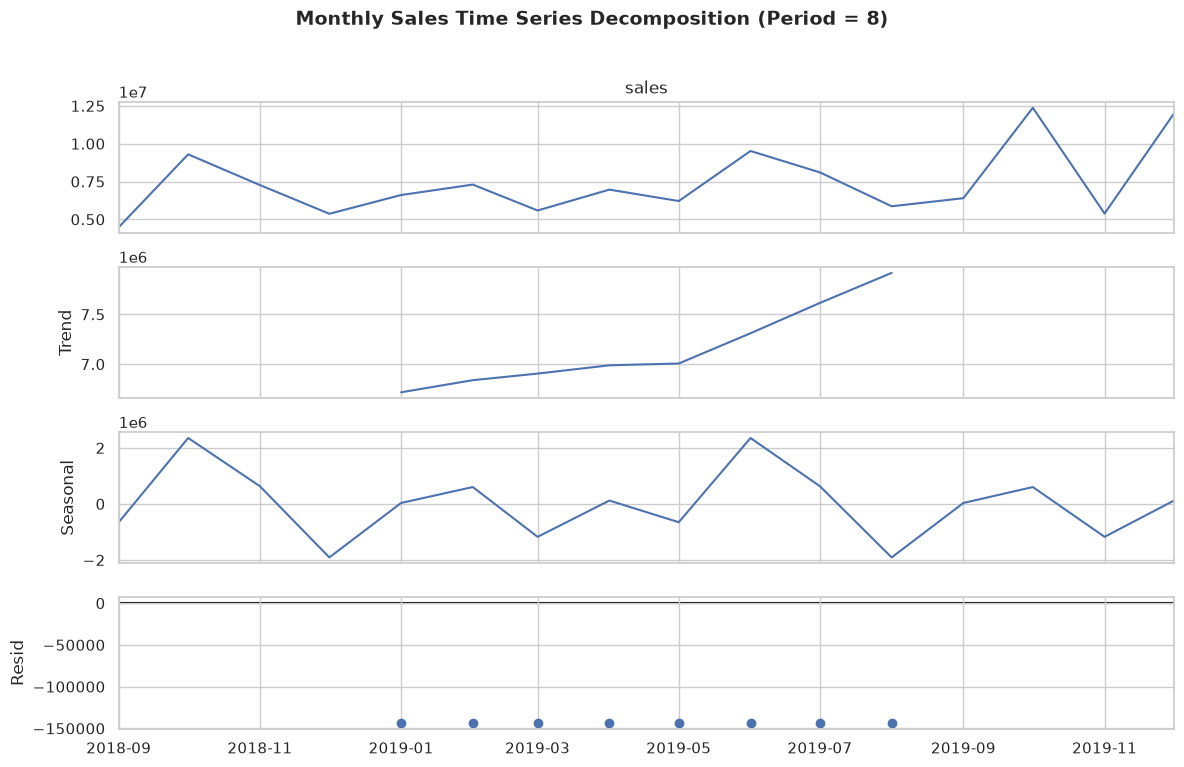

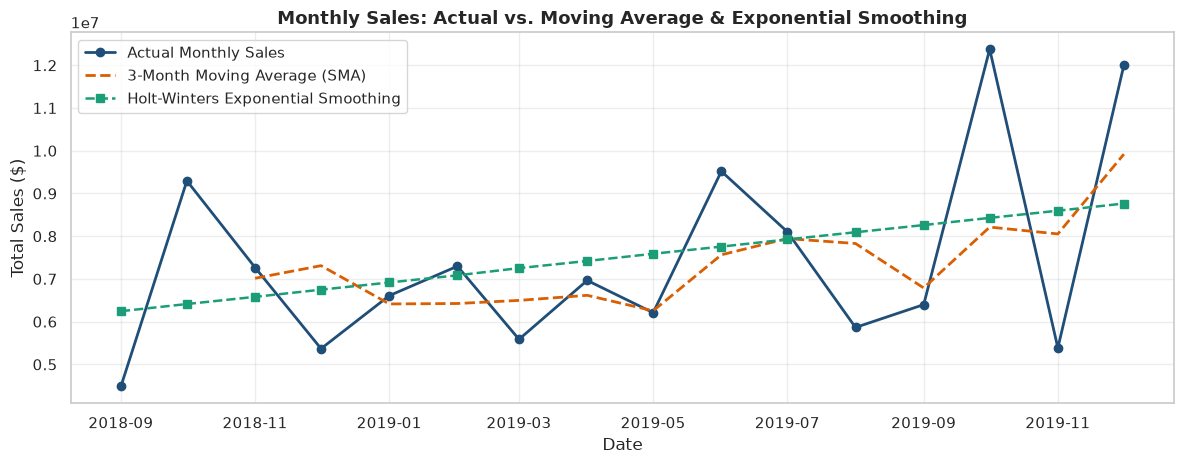

In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Parse dates (DD/MM/YYYY) and inspect temporal coverage
df_sales['dates'] = pd.to_datetime(df_sales['dates'], dayfirst=True)
print(f"Date Range: {df_sales['dates'].min().strftime('%Y-%m-%d')} to {df_sales['dates'].max().strftime('%Y-%m-%d')}")
print(f"Unique Dates: {df_sales['dates'].nunique()}")

# 2. Aggregate into a regular Monthly Sales Time Series (Month Start 'MS')
ts_monthly = df_sales.set_index('dates')['sales'].resample('MS').sum()
print(f"\nMonthly Time Series Length: {len(ts_monthly)} periods")
print(ts_monthly)

# 3. Seasonal Decomposition (Additive; adjust period if < 24 months)
decomp_period = 12 if len(ts_monthly) >= 24 else max(2, len(ts_monthly) // 2)
decomp = seasonal_decompose(ts_monthly, model='additive', period=decomp_period)

fig = decomp.plot()
fig.set_size_inches(12, 7.5)
fig.suptitle(f"Monthly Sales Time Series Decomposition (Period = {decomp_period})", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 4. Moving Average (3-Period SMA) & Holt-Winters Exponential Smoothing
sma_3 = ts_monthly.rolling(window=3).mean()
hw_model = ExponentialSmoothing(
    ts_monthly, trend='add', seasonal='add' if len(ts_monthly) >= 24 else None,
    seasonal_periods=12 if len(ts_monthly) >= 24 else None
).fit()
hw_fitted = hw_model.fittedvalues

plt.figure(figsize=(12, 4.8))
plt.plot(ts_monthly.index, ts_monthly.values, 'o-', color='#1f4e78', lw=2, label='Actual Monthly Sales')
plt.plot(sma_3.index, sma_3.values, '--', color='#d95f02', lw=2, label='3-Month Moving Average (SMA)')
plt.plot(hw_fitted.index, hw_fitted.values, 's--', color='#1b9e77', lw=1.8, label='Holt-Winters Exponential Smoothing')
plt.title("Monthly Sales: Actual vs. Moving Average & Exponential Smoothing", fontsize=13, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Total Sales ($)")
plt.legend()
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

ADF Statistic: -5.1914 | p-value: 0.0000
Stationarity Note: Stationary

--- Time Series Forecast Evaluation (4-Month Holdout: Sep–Dec 2019) ---


,Model,Test RMSE ($),Test MAE ($),AIC
0,"ARIMA (1,1,1)","$4,645,057.37","$3,497,165.54",362.04
1,"SARIMA (1,1,1)(1,0,0,4)","$4,281,064.46","$3,427,784.74",362.19



--- Out-of-Sample Forecast (Jan–Mar 2020) ---
2020-01: $6,428,094.14
2020-02: $11,707,602.23
2020-03: $7,006,683.41


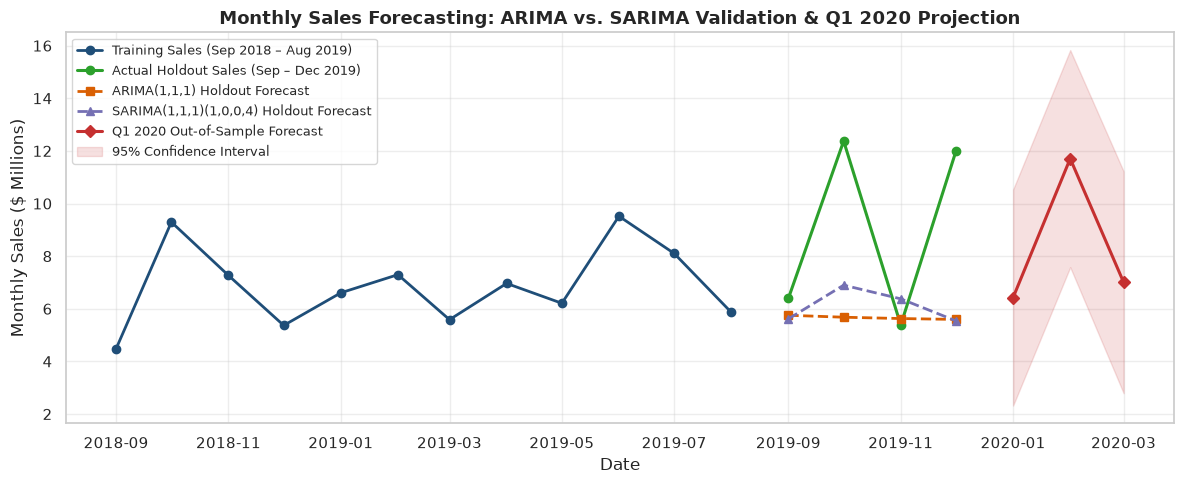

In [14]:
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Augmented Dickey-Fuller (ADF) Stationarity Test
adf_stat, adf_pval, _, _, _, _ = adfuller(ts_monthly)
print(f"ADF Statistic: {adf_stat:.4f} | p-value: {adf_pval:.4f}")
print("Stationarity Note:", "Non-stationary (requires differencing d=1)" if adf_pval > 0.05 else "Stationary")

# 2. Chronological Train/Test Split (First 12 months Train, Last 4 months Test)
train_ts = ts_monthly.iloc[:12]
test_ts = ts_monthly.iloc[12:]

# 3. Fit ARIMA(1,1,1) and SARIMA(1,1,1)(1,0,0,4) on Training Window
arima_model = ARIMA(train_ts, order=(1, 1, 1)).fit()
arima_pred = arima_model.forecast(steps=len(test_ts))

sarima_model = SARIMAX(train_ts, order=(1, 1, 1), seasonal_order=(1, 0, 0, 4)).fit(disp=False)
sarima_pred = sarima_model.forecast(steps=len(test_ts))

# 4. Evaluate Forecasting Metrics (RMSE & MAE in $ Millions)
eval_rows = []
for name, preds in [("ARIMA (1,1,1)", arima_pred), ("SARIMA (1,1,1)(1,0,0,4)", sarima_pred)]:
    rmse = np.sqrt(mean_squared_error(test_ts, preds))
    mae = mean_absolute_error(test_ts, preds)
    eval_rows.append({
        "Model": name,
        "Test RMSE ($)": f"${rmse:,.2f}",
        "Test MAE ($)": f"${mae:,.2f}",
        "AIC": round(arima_model.aic if "SARIMA" not in name else sarima_model.aic, 2)
    })

df_ts_eval = pd.DataFrame(eval_rows)
print("\n--- Time Series Forecast Evaluation (4-Month Holdout: Sep–Dec 2019) ---")
display(df_ts_eval)

# 5. Refit Best Model on Full 16-Month Series & Forecast Next 3 Months (Q1 2020)
best_full = SARIMAX(ts_monthly, order=(1, 1, 1), seasonal_order=(1, 0, 0, 4)).fit(disp=False)
future_fc = best_full.get_forecast(steps=3)
fc_mean = future_fc.predicted_mean
fc_ci = future_fc.conf_int()

print("\n--- Out-of-Sample Forecast (Jan–Mar 2020) ---")
for dt, val in fc_mean.items():
    print(f"{dt.strftime('%Y-%m')}: ${val:,.2f}")

# 6. Plot Holdout Validation & Q1 2020 Forecast
plt.figure(figsize=(12, 5))
plt.plot(train_ts.index, train_ts.values / 1e6, 'o-', color='#1f4e78', lw=2, label='Training Sales (Sep 2018 – Aug 2019)')
plt.plot(test_ts.index, test_ts.values / 1e6, 'o-', color='#2ca02c', lw=2.2, label='Actual Holdout Sales (Sep – Dec 2019)')
plt.plot(test_ts.index, arima_pred.values / 1e6, 's--', color='#d95f02', lw=2, label='ARIMA(1,1,1) Holdout Forecast')
plt.plot(test_ts.index, sarima_pred.values / 1e6, '^--', color='#7570b3', lw=2, label='SARIMA(1,1,1)(1,0,0,4) Holdout Forecast')
plt.plot(fc_mean.index, fc_mean.values / 1e6, 'D-', color='#c53030', lw=2.2, label='Q1 2020 Out-of-Sample Forecast')
plt.fill_between(fc_ci.index, fc_ci.iloc[:, 0] / 1e6, fc_ci.iloc[:, 1] / 1e6, color='#c53030', alpha=0.15, label='95% Confidence Interval')
plt.title("Monthly Sales Forecasting: ARIMA vs. SARIMA Validation & Q1 2020 Projection", fontsize=13, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Monthly Sales ($ Millions)")
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()